# Titanic outlier analysis with Winsorizer

This notebook applies Feature-engine's `Winsorizer` to the Titanic passenger data. Winsorization caps unusually small or large numeric values at learned statistical limits while keeping every passenger row.

We analyse `age`, `fare`, `sibsp`, and `parch`. `pclass` is treated as a class label rather than a continuous measurement, and `survived` is kept as the target. Post-event fields such as `boat` and `body` are excluded to avoid target leakage.

## Why outlier capping can help

A few unusually high fares or family counts can influence averages, regression estimates, and distance calculations. Capping limits that influence without deleting passengers. It should not be applied blindly: a large fare may be a genuine first-class observation, not an error. The notebook makes every learned limit and changed value visible.

In [5]:
import importlib.util, subprocess, sys
packages={"numpy":"numpy","pandas":"pandas","matplotlib":"matplotlib","seaborn":"seaborn","sklearn":"scikit-learn","feature_engine":"feature-engine"}
missing=[pkg for module,pkg in packages.items() if importlib.util.find_spec(module) is None]
if missing: subprocess.check_call([sys.executable,"-m","pip","install",*missing])
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from feature_engine.outliers import Winsorizer
sns.set_theme(style="whitegrid",context="notebook")

## 1. Load Titanic data and inspect missingness

The CSV uses `?` for missing values. We replace those markers with missing values and retain only numeric predictors for the outlier demonstration. Age and fare are imputed using training medians before fitting the outlier transformer; this prevents the transformer from failing on missing values and keeps test information out of preprocessing.

In [6]:
paths=[Path("titanic.csv"),Path("../outliers/titanic.csv"),Path("feature-engineering/outliers/titanic.csv"),Path("../encoding/titanic.csv")]
path=next((p for p in paths if p.exists()),None)
if path is None: raise FileNotFoundError("Could not find Titanic titanic.csv")
raw=pd.read_csv(path,na_values=["?"])
numeric_features=["age","fare","sibsp","parch"]
for col in numeric_features+["survived"]: raw[col]=pd.to_numeric(raw[col],errors="coerce")
print(f"Loaded {path} with {len(raw):,} passengers.")
display(raw[numeric_features+["survived"]].describe().round(2))
display(raw[numeric_features].isna().sum().rename("missing_count").to_frame())

Loaded titanic.csv with 1,309 passengers.


,age,fare,sibsp,parch,survived
count,1046.00,1308.00,1309.00,1309.00,1309.00
mean,29.88,33.30,0.50,0.39,0.38
std,14.41,51.76,1.04,0.87,0.49
min,0.17,0.00,0.00,0.00,0.00
25%,21.00,7.90,0.00,0.00,0.00
50%,28.00,14.45,0.00,0.00,0.00
75%,39.00,31.28,1.00,0.00,1.00
max,80.00,512.33,8.00,9.00,1.00


,missing_count
age,263
fare,1
sibsp,0
parch,0


## 2. Visualise the original distributions

Histograms and boxplots help distinguish skewed variables from possible extreme observations. The survival grouping is shown only for context; it is not used to learn the outlier limits.

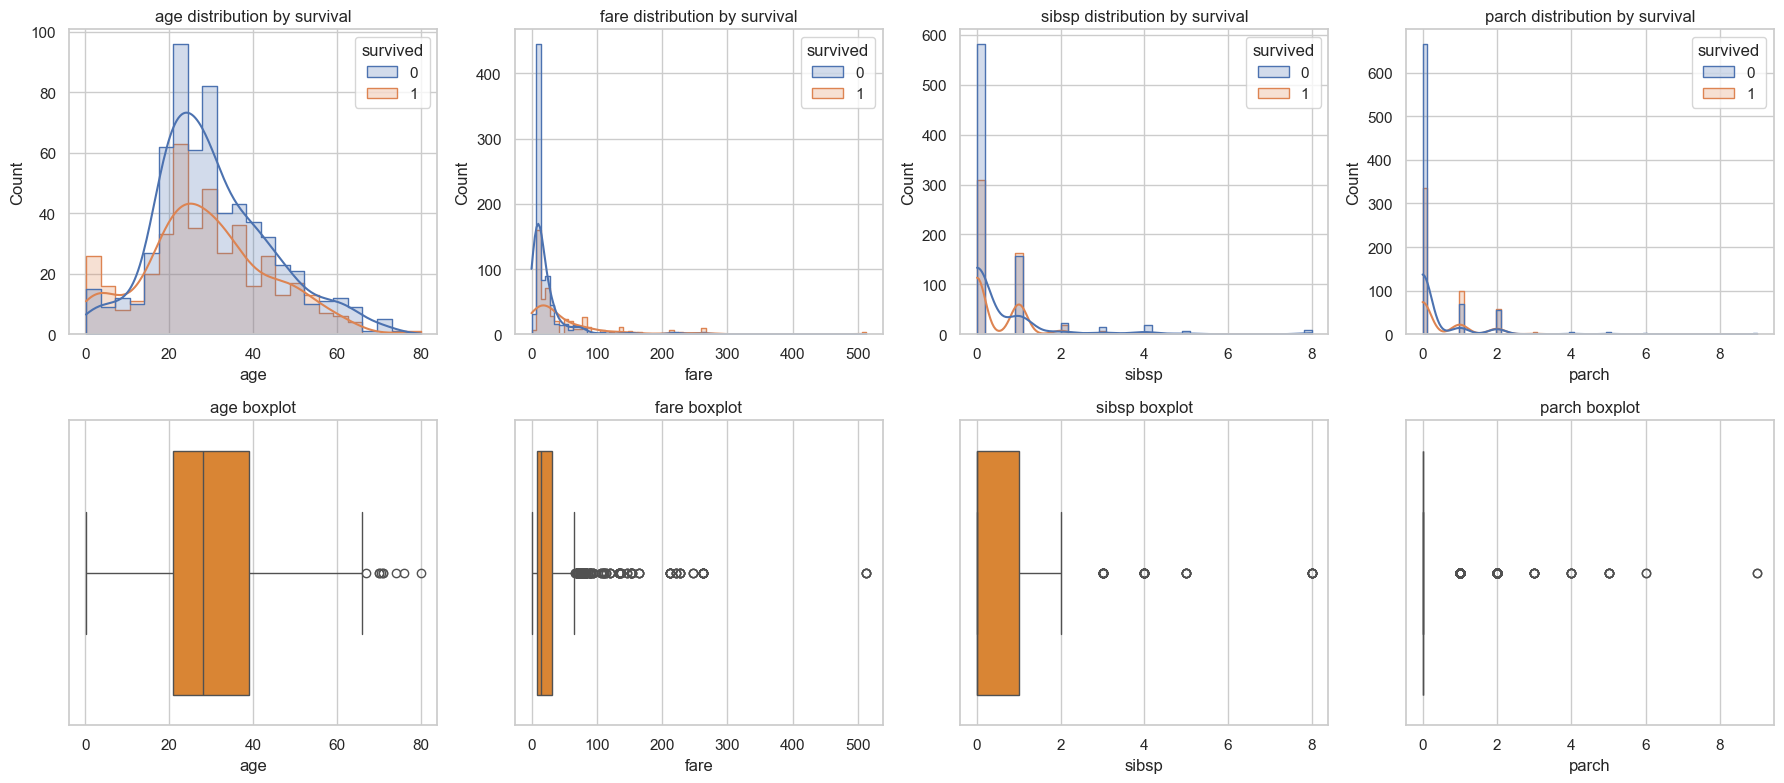

In [7]:
fig,axes=plt.subplots(2,4,figsize=(18,8))
for col,hist_ax,box_ax in zip(numeric_features,axes[0],axes[1]):
    sns.histplot(data=raw,x=col,hue="survived",kde=True,element="step",common_norm=False,ax=hist_ax)
    hist_ax.set_title(f"{col} distribution by survival")
    sns.boxplot(x=raw[col],ax=box_ax,color="#F58518")
    box_ax.set_title(f"{col} boxplot")
plt.tight_layout(); plt.show()

## 3. Split, impute, and fit IQR Winsorizer

The IQR rule uses Q1 − 1.5×IQR and Q3 + 1.5×IQR as lower and upper boundaries. We fit the median imputer and Winsorizer on the training partition only. `add_indicators=True` adds flags identifying values that were capped.
`parch` remains in the exploratory charts but is excluded from IQR capping because Feature-engine detects too little variation for a reliable IQR boundary on this discrete count variable.

In [8]:
X=raw[numeric_features].copy(); y=raw["survived"].astype(int)
outlier_features=["age","fare","sibsp"]
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.30,random_state=0,stratify=y)
imputer=SimpleImputer(strategy="median")
X_train=pd.DataFrame(imputer.fit_transform(X_train[outlier_features]),columns=outlier_features,index=X_train.index)
X_test=pd.DataFrame(imputer.transform(X_test[outlier_features]),columns=outlier_features,index=X_test.index)
winsorizer=Winsorizer(capping_method="iqr",tail="both",fold=1.5,variables=outlier_features,add_indicators=True)
winsorizer.fit(X_train)
train_capped=winsorizer.transform(X_train); test_capped=winsorizer.transform(X_test)
limits=pd.DataFrame({"lower_limit":pd.Series(winsorizer.left_tail_caps_),"upper_limit":pd.Series(winsorizer.right_tail_caps_)})
display(limits); print("Train/test rows:",len(X_train),len(X_test))

,lower_limit,upper_limit
age,2.125,55.1250
fare,-27.173,66.3438
sibsp,-1.500,2.5000


Train/test rows: 916 393


## 4. Inspect the effect of capping

Winsorization preserves row count. Values outside a learned limit become equal to that limit. The indicator columns provide an audit of how many training passengers were affected in each tail.

,raw_min,capped_min,raw_max,capped_max
age,0.3333,2.125,80.0000,55.1250
fare,0.0000,0.000,512.3292,66.3438
sibsp,0.0000,0.000,8.0000,2.5000


,capped_passengers
age_left,21.0
age_right,43.0
fare_left,0.0
fare_right,121.0
sibsp_left,0.0
sibsp_right,40.0


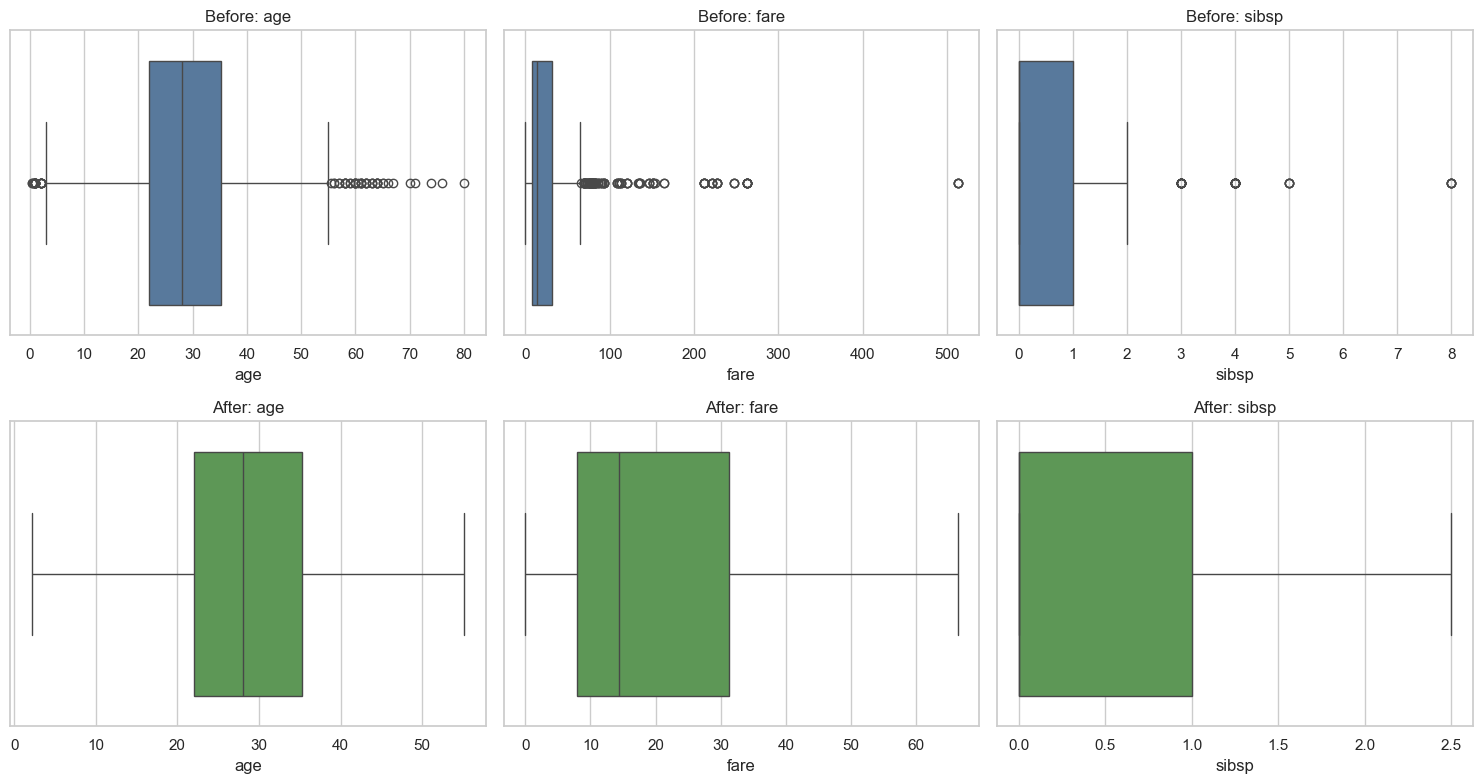

In [9]:
summary=pd.DataFrame({"raw_min":X_train.min(),"capped_min":train_capped[outlier_features].min(),"raw_max":X_train.max(),"capped_max":train_capped[outlier_features].max()})
display(summary)
indicator_cols=[c for c in train_capped.columns if c not in outlier_features]
display(train_capped[indicator_cols].sum().rename("capped_passengers").to_frame())
fig,axes=plt.subplots(2,3,figsize=(15,8))
for i,col in enumerate(outlier_features):
    sns.boxplot(x=X_train[col],ax=axes[0,i],color="#4C78A8"); axes[0,i].set_title(f"Before: {col}")
    sns.boxplot(x=train_capped[col],ax=axes[1,i],color="#54A24B"); axes[1,i].set_title(f"After: {col}")
plt.tight_layout(); plt.show()

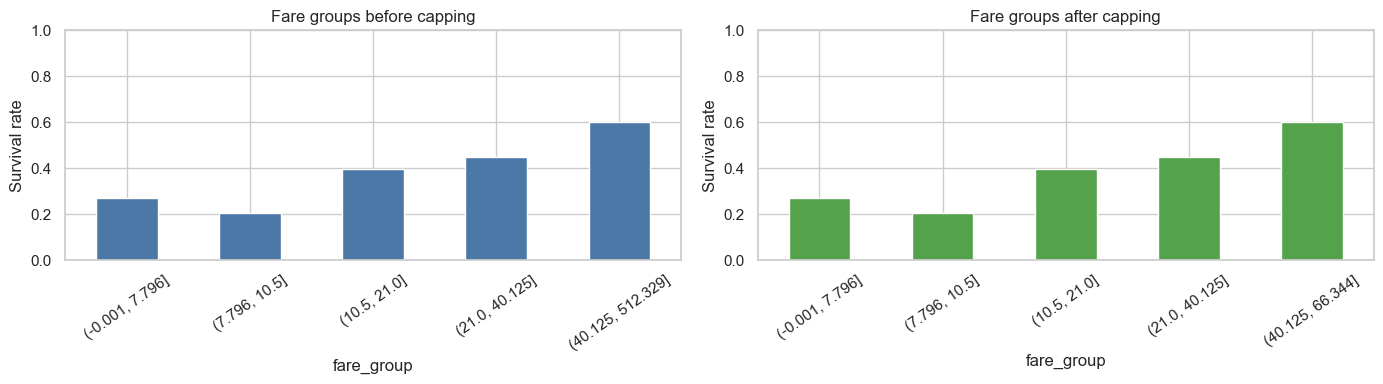

In [10]:
# Compare observed survival rates before and after adding the capped features.
before=pd.DataFrame({"fare":X_train["fare"],"survived":y_train})
before["fare_group"]=pd.qcut(before["fare"],q=5,duplicates="drop")
after=pd.DataFrame({"fare_capped":train_capped["fare"],"survived":y_train})
after["fare_group"]=pd.qcut(after["fare_capped"],q=5,duplicates="drop")
fig,axes=plt.subplots(1,2,figsize=(14,4))
before.groupby("fare_group",observed=True)["survived"].mean().plot(kind="bar",ax=axes[0],color="#4C78A8",title="Fare groups before capping")
after.groupby("fare_group",observed=True)["survived"].mean().plot(kind="bar",ax=axes[1],color="#54A24B",title="Fare groups after capping")
for ax in axes: ax.set_ylabel("Survival rate"); ax.set_ylim(0,1); ax.tick_params(axis="x",rotation=35)
plt.tight_layout(); plt.show()

## Summary and cautions

This analysis capped statistical extremes while retaining all passengers. It also made missing-value handling explicit. Capping does not prove that a value is invalid, and it can hide real first-class or family-size differences. Fit the imputer and Winsorizer on training data only, keep the learned limits with the model, and compare results with no capping or with trimming.